# 9. Decision Tree & Random Forest Classifier

## Lý thuyết & Nguyên lý

### 9.1. Decision Tree Classification — chia không gian bằng vách ngăn vuông góc

Cũng như hồi quy, cây phân loại chia không gian đặc trưng bằng các vách ngăn vuông góc với trục tọa độ. Khác biệt then chốt: tiêu chí chọn điểm chia không còn là MSE mà là các tiêu chí **độ tinh khiết của nút (node impurity)** — muốn nút con càng "thuần" một lớp càng tốt.

**Gini Impurity** (mặc định, của CART):

$$\text{Gini}(t) = 1 - \sum_{c=1}^{C} p_c^2$$

trong đó $p_c$ là tỷ lệ mẫu lớp $c$ trong nút $t$. Gini = 0 ⟺ nút hoàn toàn thuần một lớp; Gini lớn nhất khi phân bố đều ($1 - 1/C$).

**Entropy & Information Gain** (ID3/C4.5 của Quinlan):

$$H(t) = -\sum_{c=1}^{C} p_c \log_2 p_c \qquad \text{Information Gain} = H(\text{parent}) - \sum \frac{n_{\text{child}}}{n_{\text{parent}}} H(\text{child})$$

Hai tiêu chí thường cho kết quả **rất tương đương** trong thực tế; Gini nhanh hơn một chút vì không cần tính logarit.

**Pruning (cắt tỉa):** chiến lược chống overfitting — *cost-complexity pruning* với tham số $\alpha$:

$$\text{Cost} = \underbrace{\sum_{t \in \text{leaves}} N_t \cdot \text{Impurity}(t)}_{\text{training error}} + \alpha \cdot |\text{leaves}|$$

`ccp_alpha` trong scikit-learn chính là $\alpha$: tăng $\alpha$ ⇒ cây ít lá hơn, mượt hơn.

### 9.2. Random Forest Classification — bầu chọn từ nhiều cây

Giống Random Forest regression: $B$ cây trên bootstrap + tập đặc trưng ngẫu nhiên, nhưng **dự đoán cuối là phiếu bầu đa số** (hard voting) hoặc **trung bình xác suất** (soft voting, mặc định của sklearn):

$$\hat{y} = \arg\max_c \sum_{b=1}^{B} \mathbb{1}\big[T_b(x) = c\big] \quad (\text{hard}) \qquad \hat{p}_c = \frac{1}{B}\sum_{b=1}^{B} p_{b,c}(x) \quad (\text{soft})$$

Soft voting (lấy trung bình xác suất) thường **chính xác hơn** vì tận dụng được độ tự tin của từng cây. Random Forest còn cung cấp **OOB score** làm ước lượng accuracy nội bộ.


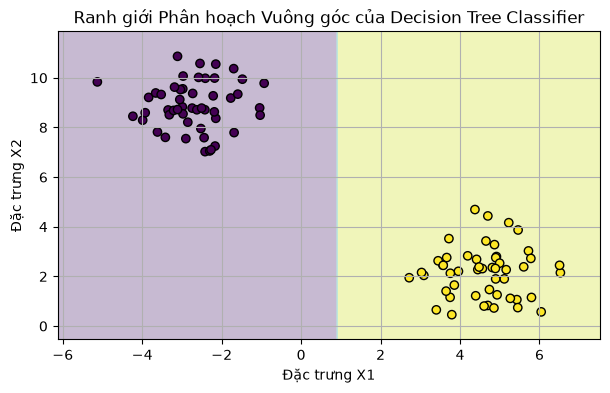

Accuracy trên dữ liệu huấn luyện: 1.0000
Các điểm chia học được:
  Node 1: X1 < 0.896


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.tree import DecisionTreeClassifier

# 1. Tạo dữ liệu 2 lớp, 2 cụm
X, y = make_blobs(n_samples=100, centers=2, random_state=42)

# 2. Huấn luyện Decision Tree Classification (độ sâu 3)
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X, y)

# 3. Vẽ ranh giới quyết định
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
    np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200),
)
Z = tree.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 4))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolor='k')
plt.title('Ranh giới Phân hoạch Vuông góc của Decision Tree Classifier')
plt.xlabel('Đặc trưng X1')
plt.ylabel('Đặc trưng X2')
plt.grid(True)
plt.show()

print(f"Accuracy trên dữ liệu huấn luyện: {tree.score(X, y):.4f}")
print("Các điểm chia học được:")
for i, (feature, threshold) in enumerate(zip(tree.tree_.feature[:tree.tree_.node_count],
                                             tree.tree_.threshold[:tree.tree_.node_count]), 1):
    if feature >= 0:
        print(f"  Node {i}: X{feature + 1} < {threshold:.3f}")


## Ý nghĩa của biểu đồ

- Ranh giới gồm các đoạn **nằm ngang và đứng** vuông góc với nhau — đặc trưng bất biến của cây quyết định: mọi điểm chia đều dạng $X_j < s$.
- Với độ sâu 3, cây chỉ tạo vài vùng chữ nhật — đủ tách 2 cụm, nhưng vẫn còn "sác cạnh" (blocky) so với ranh giới mượt của Logistic Regression hay SVM RBF.

---

## Tổng quan mô hình

### Ưu điểm

- **Ranh giới phi tuyến, dạng bậc thang** — bắt được cấu trúc dữ liệu phức tạp mà mô hình tuyến tính không với tới.
- **Không cần chuẩn hóa** dữ liệu.
- **Dễ giải thích:** trích xuất được tập luật `if-then` cho chuyên gia nghiệp vụ.
- **Đo lường độ quan trọng đặc trưng** (`feature_importances_`), xử lý được cả đặc trưng phân loại (mã hóa hợp lý).
- **Random Forest:** hiệu năng cao, ít tinh chỉnh, robust với noise; có OOB score.

### Nhược điểm

- **Cây đơn phương sai cao** — dễ overfitting; ranh giới bậc thang thô, không ngoại suy.
- **Cây đơn không ổn định:** thay đổi nhỏ dữ liệu có thể sinh cây hoàn toàn khác (variance cao).
- **Multiclass khó hơn:** ranh giới chia theo lát (OvR), dữ liệu lệch lớp ảnh hưởng mạnh tiêu chí Gini/Entropy.
- **Random Forest khó diễn giải** hơn cây đơn, tốn tài nguyên tính toán hơn.

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `criterion` | 'gini' (mặc định) hoặc 'entropy' | Thường không đổi kết quả nhiều; thử cả hai |
| `max_depth` | Giới hạn chiều sâu, chống overfitting | Cây đơn: 3–10; RF: `None` |
| `min_samples_leaf` | Số mẫu tối thiểu trong lá | Tăng lên để ranh giới mượt, ít overfit |
| `ccp_alpha` | Hệ số cắt tỉa cost-complexity | Quét thang log để tìm giá trị tối ưu |
| `max_features` | Số đặc trưng mỗi điểm chia (RF) | Classification: `sqrt`; Regression: `1.0` |
| `class_weight` | Cân bằng trọng số lớp | 'balanced' khi dữ liệu lệch lớp mạnh |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Lớp ($Y$) |
| :--- | :--- | :--- | :--- |
| **Tài chính** | Chấm điểm tín dụng giải thích được | Thu nhập, nợ, lịch sử giao dịch | Duyệt / Từ chối |
| **Y tế** | Hỗ trợ chẩn đoán theo luật | Triệu chứng, chỉ số xét nghiệm, tuổi | Có bệnh / Không |
| **Bảo mật** | Phát hiện xâm nhập mạng | Cổng, lưu lượng, gói tin bất thường | Tấn công / Bình thường |
| **Nông nghiệp** | Chẩn đoán bệnh cây trồng | Đặc trưng lá ảnh, nhiệt độ, độ ẩm | Lá khỏe / Lá bệnh |
| **Sản xuất** | Phân loại phế phẩm QC | Kích thước, màu sắc, trọng lượng, độ nhám | Đạt / Lỗi |

### Mẹo thực hành

- Luôn plot ranh giới quyết định trên dữ liệu 2D để "thấy" mô hình học được gì — kỹ năng trực quan hóa cực kỳ hữu ích khi debug.
- Random Forest với `class_weight='balanced'` + `max_features='sqrt'` là cấu hình mặc định mạnh cho bài toán phân loại bảng.
- So sánh `feature_importances_` của Random Forest với hệ số của Logistic Regression — nếu hai mô hình "bất đồng ý", dữ liệu nhiều phi tuyến hoặc nhiều tương tác.


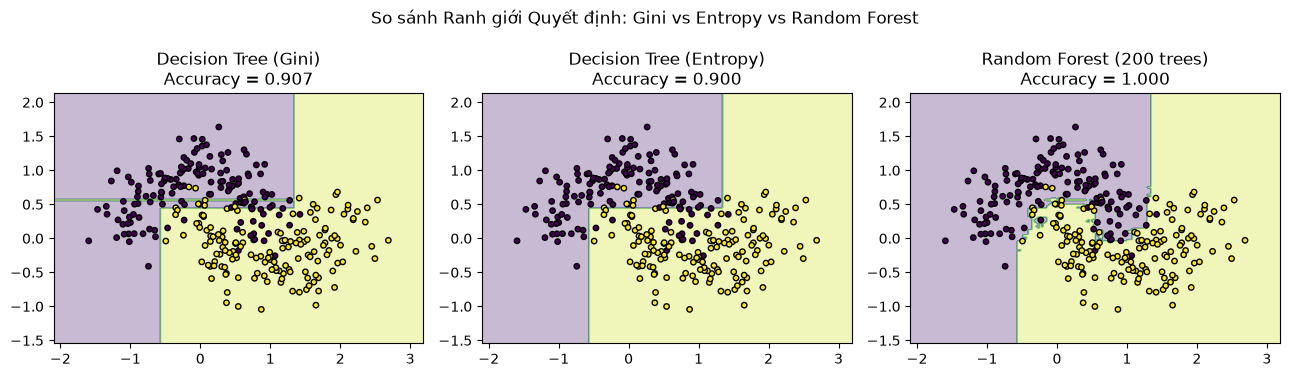

Feature importances của Random Forest: [0.46 0.54]


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

# 1. Dữ liệu 2 lớp dạng hai nửa mặt trăng (phi tuyến, khó cho cây đơn)
X, y = make_moons(n_samples=300, noise=0.25, random_state=42)

# 2. Huấn luyện 3 mô hình: Gini, Entropy, và Random Forest
models = {
    'Decision Tree (Gini)': DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42),
    'Decision Tree (Entropy)': DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42),
    'Random Forest (200 trees)': RandomForestClassifier(n_estimators=200, random_state=42),
}

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
    np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200),
)
grid = np.c_[xx.ravel(), yy.ravel()]

plt.figure(figsize=(13, 3.8))
for i, (name, model) in enumerate(models.items(), 1):
    model.fit(X, y)
    acc = accuracy_score(y, model.predict(X))
    Z = model.predict(grid).reshape(xx.shape)

    plt.subplot(1, 3, i)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolor='k', s=15)
    plt.title(f'{name}\nAccuracy = {acc:.3f}')

plt.suptitle('So sánh Ranh giới Quyết định: Gini vs Entropy vs Random Forest')
plt.tight_layout()
plt.show()

rf = models['Random Forest (200 trees)']
print(f"Feature importances của Random Forest: {np.round(rf.feature_importances_, 3)}")


## Giải thích kết quả

- **Gini vs Entropy:** hai ranh giới gần như **giống hệt** nhau — minh chứng phổ biến trong thực tế: lựa chọn tiêu chí impurity hiếm khi là yếu tố quyết định hiệu năng; **điều chỉnh độ sâu và số lá mới là chìa khóa**.
- **Random Forest:** ranh giới mượt, uốn theo hình hai nửa mặt trăng — nhờ trung bình nhiều cây, từng bước nhảy bậc thang nhỏ được "mịn hóa".
- **Feature importance** in ra xác nhận hai trục $X_1, X_2$ trong dữ liệu `make_moons` gần như đóng góp ngang nhau.
